# Step 1: Install Required Libraries

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

# Step 2: Load the Weather Dataset

In [2]:
import pandas as pd

# URL of the dataset on Zenodo
url = 'https://zenodo.org/record/4770937/files/weather_prediction_dataset.csv'

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(url)

# Display the first few rows of dataset
print(df.head())

       DATE  MONTH  BASEL_cloud_cover  BASEL_humidity  BASEL_pressure  \
0  20000101      1                  8            0.89          1.0286   
1  20000102      1                  8            0.87          1.0318   
2  20000103      1                  5            0.81          1.0314   
3  20000104      1                  7            0.79          1.0262   
4  20000105      1                  5            0.90          1.0246   

   BASEL_global_radiation  BASEL_precipitation  BASEL_sunshine  \
0                    0.20                 0.03             0.0   
1                    0.25                 0.00             0.0   
2                    0.50                 0.00             3.7   
3                    0.63                 0.35             6.9   
4                    0.51                 0.07             3.7   

   BASEL_temp_mean  BASEL_temp_min  ...  STOCKHOLM_temp_min  \
0              2.9             1.6  ...                -9.3   
1              3.6             2.7  ..

In [3]:
# Display basic info on the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3654 entries, 0 to 3653
Columns: 165 entries, DATE to TOURS_temp_max
dtypes: float64(150), int64(15)
memory usage: 4.6 MB


In [4]:
# Display summary statistics
print(df.describe())

               DATE        MONTH  BASEL_cloud_cover  BASEL_humidity  \
count  3.654000e+03  3654.000000        3654.000000     3654.000000   
mean   2.004568e+07     6.520799           5.418446        0.745107   
std    2.874287e+04     3.450083           2.325497        0.107788   
min    2.000010e+07     1.000000           0.000000        0.380000   
25%    2.002070e+07     4.000000           4.000000        0.670000   
50%    2.004567e+07     7.000000           6.000000        0.760000   
75%    2.007070e+07    10.000000           7.000000        0.830000   
max    2.010010e+07    12.000000           8.000000        0.980000   

       BASEL_pressure  BASEL_global_radiation  BASEL_precipitation  \
count     3654.000000             3654.000000          3654.000000   
mean         1.017876                1.330380             0.234849   
std          0.007962                0.935348             0.536267   
min          0.985600                0.050000             0.000000   
25%       

# Step 3: Check Missing Values

In [5]:
print(df.isnull().sum())

DATE                      0
MONTH                     0
BASEL_cloud_cover         0
BASEL_humidity            0
BASEL_pressure            0
                         ..
TOURS_global_radiation    0
TOURS_precipitation       0
TOURS_temp_mean           0
TOURS_temp_min            0
TOURS_temp_max            0
Length: 165, dtype: int64


# Step 4: Data Preprocessing

In [9]:
# 1.Handle missing Values
df=df.dropna()

In [10]:
# 2. Perform on-hot encoding on categorical variables
df=pd.get_dummies(df, drop_first=True)

In [11]:
# 3. Feature Selection 
# Define featrues and target variable

X = df.drop('BASEL_temp_mean', axis=1)
y = df['BASEL_temp_mean']

# Step 5: Split the data 

In [12]:
from sklearn.model_selection import train_test_split

#Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 6: Build and Train the Model

In [13]:
from sklearn.linear_model import LinearRegression

# Initialize the model
model = LinearRegression()

# Train the Model
model.fit(X_train, y_train)

LinearRegression()

# Step 7: Evaluate the Model

In [14]:
from sklearn.metrics import mean_squared_error, r2_score

# Make Predictions
y_pred = model.predict(X_test)

# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

# Calculate R-Squared Score
r2 = r2_score(y_test, y_pred)
print(f'R-Squared Score" {r2}') 

Mean Squared Error: 0.19665724668455836
R-Squared Score" 0.9963551645217837


# Step 8: Visualize the Results

Matplotlib is building the font cache; this may take a moment.


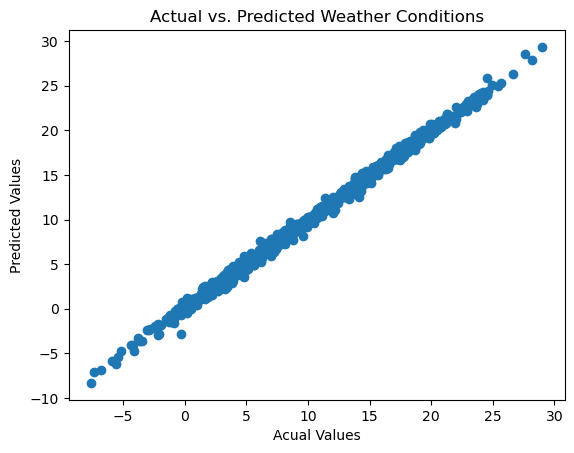

In [15]:
import matplotlib.pyplot as plt

# Plot actual vs. predicted values
plt.scatter(y_test, y_pred)
plt.xlabel('Acual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Weather Conditions')
plt.show()